<a href="https://colab.research.google.com/github/Giocrisrai/aprendizaje-refuerzo-duoc/blob/main/notebooks/06_algoritmo_genetico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# 06 · Algoritmo genético
**Machine Learning — Duoc UC**

Q-learning anota, para cada casilla, qué tan buena es cada acción. Un algoritmo genético no anota nada: propone rutas enteras, se queda con las que más retorno dan, las mezcla y les cambia un paso al azar.

| Pieza | En esta clase |
|---|---|
| Individuo | una lista de ceros y unos, o una lista de acciones |
| Aptitud | cuántos bits atinó, o el retorno de jugar esa ruta |
| Selección | torneo de 3: gana el de mayor aptitud |
| Cruce | se corta en un punto y se pegan las dos mitades |
| Mutación | se voltea un bit, o se cambia una acción |

Misma grilla del notebook 01, para que la comparación se vea.


In [1]:
#@title ⚙️ Configuración (ejecutar primero — en Colab clona el repositorio, sin subir archivos)
import os, sys, subprocess, glob

REPO_URL = "https://github.com/Giocrisrai/aprendizaje-refuerzo-duoc"
EN_COLAB = "google.colab" in sys.modules
ARCHIVOS = ("rl_utils.py", "salmon_env.py", "grilla.py", "evolucion.py")
DATOS = (
    "../data/runs_cliffwalking.csv",
    "../data/historial_inventario.csv",
    "../data/historial_operador_salmon.csv",
)

def buscar_notebooks():
    """Carpeta que contiene los .py de la clase, o None."""
    if all(os.path.exists(nombre) for nombre in ARCHIVOS):
        return os.getcwd()
    candidatos = [
        "/content/aprendizaje-refuerzo-duoc/notebooks",
        "/content/rl_aprendizaje_refuerzo/notebooks",
    ]
    candidatos += glob.glob("/content/**/notebooks", recursive=True)
    vistos = []
    for carpeta in candidatos:
        if carpeta in vistos or not os.path.isdir(carpeta):
            continue
        vistos.append(carpeta)
        if all(os.path.exists(os.path.join(carpeta, nombre)) for nombre in ARCHIVOS):
            return carpeta
    return None

if EN_COLAB and buscar_notebooks() is None:
    subprocess.run(
        ["git", "clone", "-q", "--depth", "1", REPO_URL, "/content/aprendizaje-refuerzo-duoc"],
        check=False,
    )

carpeta = buscar_notebooks()
if carpeta is None:
    raise FileNotFoundError(
        "No encuentro " + ", ".join(ARCHIVOS) + ". "
        "En Colab esta celda clona el repositorio: ahí están los módulos y data/. "
        "En el computador, abre el notebook desde la carpeta notebooks/."
    )
os.chdir(carpeta)

if EN_COLAB:
    req = os.path.abspath(os.path.join(os.getcwd(), "..", "requirements.txt"))
    if os.path.exists(req):
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", req])
try:
    import numpy, pandas, matplotlib
except ImportError as exc:
    raise ImportError("Faltan numpy, pandas o matplotlib. En local, desde la raíz del repositorio: uv sync --group dev") from exc
faltan = [ruta for ruta in DATOS if not os.path.exists(ruta)]
if faltan:
    raise FileNotFoundError("Faltan datos del repositorio: " + ", ".join(faltan))
print("✅ Listo. Carpeta de trabajo:", os.getcwd(), "| Colab" if EN_COLAB else "| local")
print("Librerías:", "numpy", numpy.__version__, "| pandas", pandas.__version__, "| matplotlib", matplotlib.__version__)


✅ Listo. Carpeta de trabajo: /Users/giocrisraigodoy/Documents/DUOC/2026-2/rl_clase/notebooks | local


## Bits
Dieciséis bits fijos. La aptitud es la cantidad de aciertos. Con población 80 suele terminar en pocas generaciones.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from evolucion import evolucionar_bits, evolucionar_ruta

objetivo = np.array([1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1])
mejor, historia_bits = evolucionar_bits(objetivo, semilla=0)
print("bits correctos:", int((mejor == objetivo).sum()), "de", len(objetivo))
print("generaciones:  ", len(historia_bits))


bits correctos: 16 de 16
generaciones:   6


## La misma grilla, sin tabla
El cromosoma es una secuencia de 6 acciones (0 arriba, 1 abajo, 2 izquierda, 3 derecha). Si el héroe ya tomó el trofeo, el resto no se juega. Q-learning, en el notebook 01, saca **997**. Mira si el genético empata o si llega dando vueltas.


llegó   : True
retorno : 995.0   (Q-learning sacaba 997)
camino  : [(2, 0), (2, 0), (2, 1), (1, 1), (0, 1), (0, 1), (0, 0)]


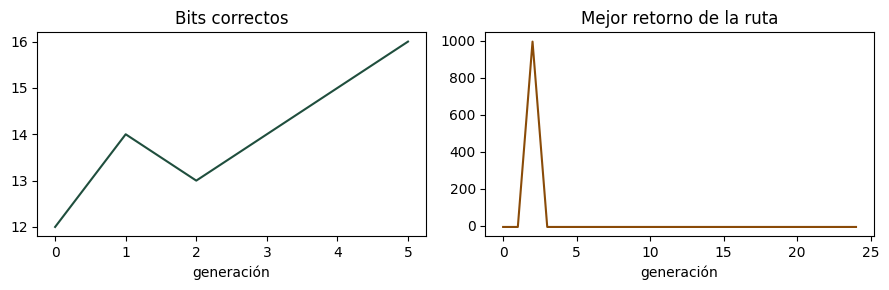

In [3]:
genes, historia_ruta, camino, retorno, llego = evolucionar_ruta(semilla=0)
print("llegó   :", llego)
print("retorno :", retorno, "  (Q-learning sacaba 997)")
print("camino  :", camino)

fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
ejes[0].plot(historia_bits, color="#1f4e3d")
ejes[0].set_title("Bits correctos")
ejes[0].set_xlabel("generación")
ejes[1].plot(historia_ruta, color="#8a4b08")
ejes[1].set_title("Mejor retorno de la ruta")
ejes[1].set_xlabel("generación")
fig.tight_layout()
plt.show()


Si el retorno es 995 o 996, llegó y gastó pasos (chocar con el borde también cobra −1). La tabla del notebook 01 generaliza a otras salidas; esta ruta solo sirve para este mapa y este largo. Esa es la diferencia que hay que poder decir.

## Ejercicio · la mochila
Cuatro objetos. Pesos `[2, 3, 4, 5]`, valores `[3, 4, 5, 8]`, capacidad 8. La aptitud es la suma de valores si el peso cabe, y **0** si se pasa. Un gen es 0 o 1: llevar o no llevar.

Los bits y la ruta del héroe son el ejemplo de la clase. **La mochila es la tarea.**

Para ver el algoritmo con otro ejemplo (una frase que aparece sola): [The Coding Train, 9.2, cómo funciona](https://www.youtube.com/watch?v=RxTfc4JLYKs). La idea, antes del algoritmo: [9.1](https://www.youtube.com/watch?v=9zfeTw-uFCw). Inglés.

Los bits y la ruta quedan resueltos en este notebook. Sigue en `07_programacion_genetica.ipynb`: ahí el individuo es un árbol, no una lista.


In [4]:
def aptitud_mochila_estudiante(bits, pesos, valores, capacidad):
    raise NotImplementedError("completa esta función")


In [5]:
import numpy as np
from evolucion import aptitud_mochila, evolucionar_mochila

pesos, valores, capacidad = [2, 3, 4, 5], [3, 4, 5, 8], 8
try:
    assert aptitud_mochila_estudiante([0, 1, 0, 1], pesos, valores, capacidad) == 12
    assert aptitud_mochila_estudiante([1, 1, 1, 1], pesos, valores, capacidad) == 0
    mejor, _ = evolucionar_mochila(pesos, valores, capacidad, semilla=0)
    print("✅ Cabe y no se pasa. El algoritmo, con la aptitud del módulo, se queda con",
          list(map(int, mejor)), "y valor", aptitud_mochila(mejor, pesos, valores, capacidad))
except NotImplementedError:
    print("Pendiente: completa aptitud_mochila_estudiante.")
except AssertionError:
    print("El individuo [0, 1, 0, 1] pesa 8 y vale 12. Llevar los cuatro se pasa: aptitud 0.")


Pendiente: completa aptitud_mochila_estudiante.


In [6]:
#@title 💡 Solución ejercicio (doble clic para ver el código)
import numpy as np

def aptitud_mochila_estudiante(bits, pesos, valores, capacidad):
    bits = np.asarray(bits, dtype=float)
    pesos = np.asarray(pesos, dtype=float)
    valores = np.asarray(valores, dtype=float)
    if float(bits @ pesos) > capacidad:
        return 0.0
    return float(bits @ valores)
